In [1]:
# Notebook: P7_Figures_v02.ipynb | Cell 1: settings, data loading, joins and map helpers
# Run Cells 1-9 in order. Every figure is drawn only from saved project outputs (no model is re-run).
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio.features
from affine import Affine
from shapely.geometry import shape
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

# ---- Settings ----
ROOT = Path(r"D:\Siam\Thesis_GeoAI")
MODELS = ROOT / "05_models"
MASTER = ROOT / "04_master_table" / "master_v06_20261020.csv"
LABELS = ROOT / "03_features" / "Label_Flooded_Event_v01.csv"
OBS_MASK = ROOT / "03_features" / "Observability_Mask_v01.csv"
IBTRACS = ROOT / "01_raw" / "ibtracs" / "ibtracs.NI.list.v04r01.csv"
OUT = ROOT / "07_maps_figures" / "thesis_v02"
X0, Y0, RES, NCOL, NROW = 142750.0, 2545500.0, 250.0, 615, 556   # Y0 = top edge of the grid
CRS = "EPSG:32646"
N_GRID, N_MODEL = 218035, 160874
DPI = 300
SEED = 42
EVENTS = ["Amphan", "Yaas", "Remal"]
STORMS = {"Amphan": "2020136N10088", "Yaas": "2021143N15090", "Remal": "2024145N14087"}
FEATS = ["Elevation_Mean_m", "Slope_Mean_deg", "Distance_to_River_m", "Cropland_Fraction"]
FEAT_LABEL = {"Elevation_Mean_m": "Elevation (m)", "Slope_Mean_deg": "Slope (deg)",
              "Distance_to_River_m": "Distance to river (m)", "Cropland_Fraction": "Cropland fraction"}
WATER_COLOR = "#cfe3f3"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "figure.dpi": 100})
OUT.mkdir(parents=True, exist_ok=True)
SAVED = []

# ---- Master (all grid cells, for water and boundaries) ----
mcols = ["Grid_ID", "District", "Upazila", "Is_Water", "Centroid_X_m", "Centroid_Y_m",
         "Elevation_Mean_m", "Slope_Mean_deg", "Distance_to_River_m", "Cropland_Fraction", "Tree_Fraction",
         "Mangrove_Fraction_GMW", "Population_Count", "Poverty_Rate_Upazila_Pct",
         "Distance_to_Hospital_m", "Distance_to_Road_m", "Wind_RP100yr_ms", "Storm_Tide_RP100yr_m"]
mall = pd.read_csv(MASTER, usecols=mcols)
assert len(mall) == N_GRID and mall["Grid_ID"].is_unique, "Master row count / Grid_ID problem"
mall["col"] = np.floor((mall["Centroid_X_m"] - X0) / RES).astype(int)
mall["row"] = np.floor((Y0 - mall["Centroid_Y_m"]) / RES).astype(int)
assert mall["col"].between(0, NCOL - 1).all() and mall["row"].between(0, NROW - 1).all()
assert not (mall["row"] * NCOL + mall["col"]).duplicated().any(), "Two cells share one pixel"
POS = mall.set_index("Grid_ID")[["row", "col"]]

# ---- Model cells joined with all saved outputs ----
v03 = pd.read_csv(MODELS / "final_v03" / "hazard_predictions_v03.csv").drop(columns="District")
v02 = pd.read_csv(MODELS / "final_v02" / "hazard_predictions_v02.csv", usecols=["Grid_ID", "Hazard_Prob_LGBM"])
v02 = v02.rename(columns={"Hazard_Prob_LGBM": "Hazard_Prob_LGBM_v02"})
p5 = pd.read_csv(MODELS / "phase5_v01" / "phase5_risk_v01.csv")
p4 = pd.read_csv(MODELS / "phase4_v01" / "phase4_shap_ensemble_v01.csv")
p6 = pd.read_csv(MODELS / "phase6_v01" / "phase6_priority_v01.csv")
d = mall[mall["Is_Water"] == 0].drop(columns="Is_Water")
for t in [v03, v02, p5, p4, p6]:
    d = d.merge(t, on="Grid_ID", how="inner", validate="one_to_one")
assert len(d) == N_MODEL, f"Join lost rows: {len(d)}"
need = ["Hazard_Prob_LGBM", "Hazard_Prob_LGBM_v02", "Unobservable_Reason", "Is_Within_AOA", "H_Index", "E_Index",
        "V_Index", "Risk_Rank_Pct", "Is_Top10_Risk", "Risk_MC_Rank_P05_Pct", "Risk_MC_Rank_P95_Pct",
        "Hazard_Ens_Rank_SD_Pct", "Priority_Class_Code", "Is_Hidden_Hazard"] + \
       [f"Risk_Rank_Pct_{s}" for s in ["SSP245_2100", "SSP585_2100"]] + [f"SHAP_LogOdds_{f}" for f in FEATS]
nn = d[need].isna().sum()
assert nn.sum() == 0, f"NaN in required columns: {nn[nn > 0].to_dict()}"

def pct_mid(x):
    x = pd.Series(np.asarray(x, dtype="float64"))
    return ((x.rank(method="average") - 0.5) / len(x)).to_numpy()

def wmean(v, w):
    v, w = np.asarray(v, float), np.asarray(w, float)
    return float((v * w).sum() / w.sum())

d["Pct_v03"] = pct_mid(d["Hazard_Prob_LGBM"])
d["Pct_v02"] = pct_mid(d["Hazard_Prob_LGBM_v02"])
print(f"Model cells joined: {len(d):,} | population {d['Population_Count'].sum():,.0f}")

# ---- Raster helpers and boundaries traced from the grid (aligned with cells) ----
def to_grid(gids, values):
    a = np.full((NROW, NCOL), np.nan)
    rc = POS.loc[np.asarray(gids)]
    a[rc["row"].to_numpy(), rc["col"].to_numpy()] = np.asarray(values, dtype="float64")
    return a

TRANSFORM = Affine(RES, 0, X0, 0, -RES, Y0)
EXTENT = [X0, X0 + NCOL * RES, Y0 - NROW * RES, Y0]

def trace(colname):
    codes = {v: i + 1 for i, v in enumerate(sorted(mall[colname].unique()))}
    arr = np.zeros((NROW, NCOL), dtype="int32")
    arr[mall["row"], mall["col"]] = mall[colname].map(codes).to_numpy()
    parts = [(shape(g), int(v)) for g, v in rasterio.features.shapes(arr, mask=arr > 0, transform=TRANSFORM)]
    g = gpd.GeoDataFrame({"code": [v for _, v in parts]}, geometry=[p for p, _ in parts], crs=CRS)
    g = g.dissolve("code").reset_index()
    g[colname] = g["code"].map({v: k for k, v in codes.items()})
    return g

DIST = trace("District")
UPZ = trace("Upazila")
assert len(DIST) == 5, f"Expected 5 districts, got {len(DIST)}"
print("Districts:", list(DIST["District"]), "| upazilas traced:", len(UPZ))
minx, miny, maxx, maxy = DIST.total_bounds
PAD = 3000
BBOX = (minx - PAD, maxx + PAD, miny - PAD, maxy + PAD)
WATER = to_grid(mall["Grid_ID"], np.where(mall["Is_Water"] == 1, 1.0, np.nan))

def north_arrow(ax):
    ax.annotate("N", xy=(0.94, 0.96), xytext=(0.94, 0.86), xycoords="axes fraction", ha="center",
                va="center", fontsize=10, fontweight="bold",
                arrowprops=dict(facecolor="black", edgecolor="black", width=2.5, headwidth=8))

def scale_bar(ax, length_km=20):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    sx, sy = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    L = length_km * 1000
    ax.plot([sx, sx + L / 2], [sy, sy], color="black", lw=3, solid_capstyle="butt", zorder=6)
    ax.plot([sx + L / 2, sx + L], [sy, sy], color="white", lw=3, solid_capstyle="butt", zorder=6)
    ax.plot([sx, sx + L], [sy, sy], color="black", lw=0.6, zorder=6)
    dy = 0.02 * (y1 - y0)
    for xv, t in [(sx, "0"), (sx + L / 2, f"{length_km // 2}"), (sx + L, f"{length_km} km")]:
        ax.text(xv, sy + dy, t, ha="center", va="bottom", fontsize=7, zorder=6)

def base_map(ax, letter=None, title=None, upazila=False):
    ax.imshow(WATER, extent=EXTENT, cmap=ListedColormap([WATER_COLOR]), interpolation="nearest", zorder=0)
    if upazila:
        UPZ.boundary.plot(ax=ax, color="0.45", linewidth=0.25, zorder=3)
    DIST.boundary.plot(ax=ax, color="black", linewidth=0.6, zorder=4)
    ax.set_xlim(BBOX[0], BBOX[1])
    ax.set_ylim(BBOX[2], BBOX[3])
    ax.set_aspect("equal")
    ax.set_axis_off()
    north_arrow(ax)
    scale_bar(ax)
    if letter:
        ax.text(0.02, 0.98, f"({letter})", transform=ax.transAxes, ha="left", va="top",
                fontsize=11, fontweight="bold")
    if title:
        ax.set_title(title)

def show_cont(ax, gids, values, cmap, label, fig, vmin=None, vmax=None, norm=None, extend="neither"):
    arr = to_grid(gids, values)
    kw = {"norm": norm} if norm is not None else {"vmin": vmin, "vmax": vmax}
    im = ax.imshow(arr, extent=EXTENT, cmap=cmap, interpolation="nearest", zorder=1, **kw)
    cb = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.01, extend=extend)
    cb.set_label(label)
    return im

def show_cat(ax, gids, codes, colors, labels, loc="lower right"):
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(0.5, len(colors) + 1.5), len(colors))
    ax.imshow(to_grid(gids, codes), extent=EXTENT, cmap=cmap, norm=norm, interpolation="nearest", zorder=1)
    ax.legend(handles=[Patch(facecolor=c, edgecolor="0.3", lw=0.3, label=l) for c, l in zip(colors, labels)],
              loc=loc, frameon=True, framealpha=0.9)

def save(fig, name):
    p = OUT / f"{name}.png"
    fig.savefig(p, dpi=DPI, bbox_inches="tight", facecolor="white")
    SAVED.append(p.name)
    plt.show()
    plt.close(fig)
    print("Saved:", p.name)

print("CELL 1 OK")


Model cells joined: 160,874 | population 7,725,116
Districts: ['Bagerhat', 'Barguna', 'Bhola', 'Patuakhali', 'Pirojpur'] | upazilas traced: 37
CELL 1 OK


Track Amphan: 51 points
Track Yaas: 39 points
Track Remal: 40 points
No *adm0* file found in 01_raw: panel (a) is drawn without the national outline


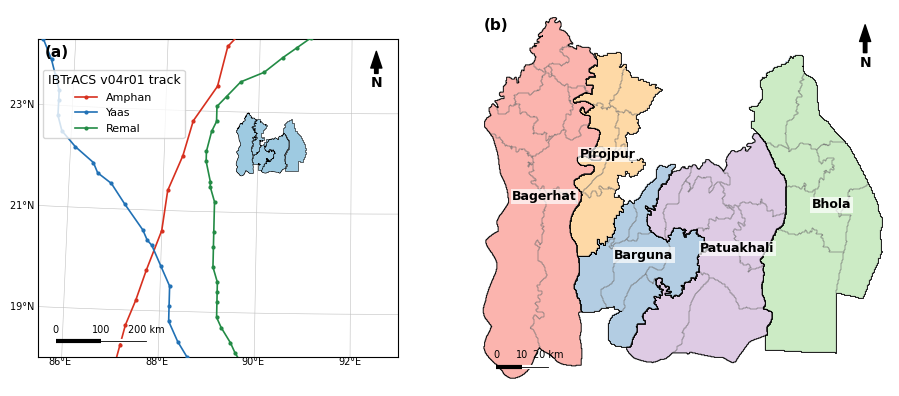

Saved: Fig3_01_StudyArea_Tracks.png


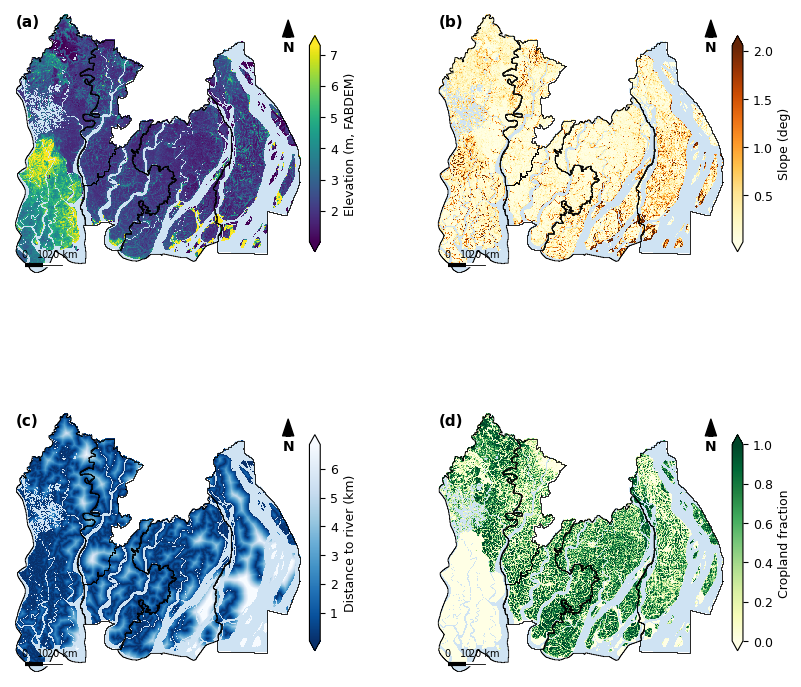

Saved: Fig3_02_Hazard_Predictors.png


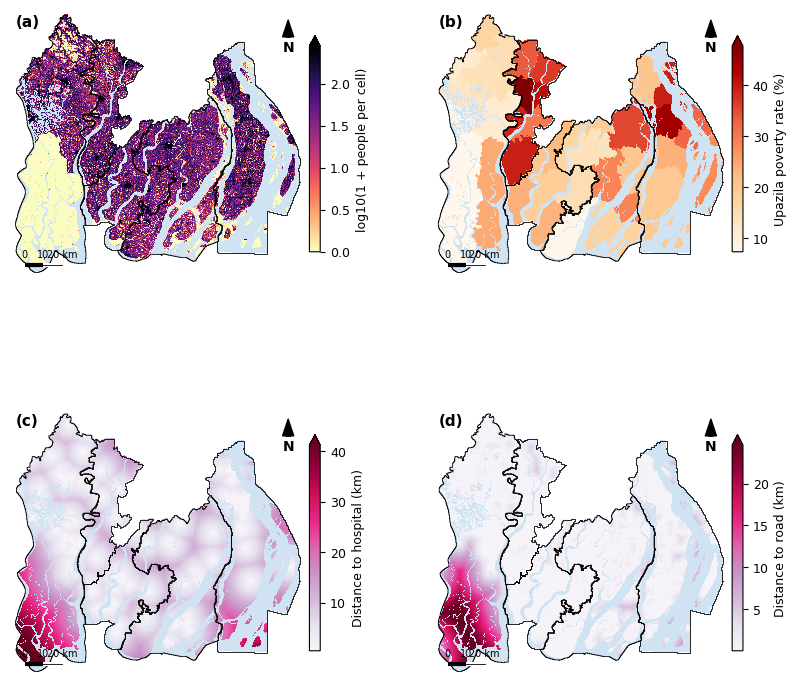

Saved: Fig3_03_Exposure_Vulnerability_Inputs.png


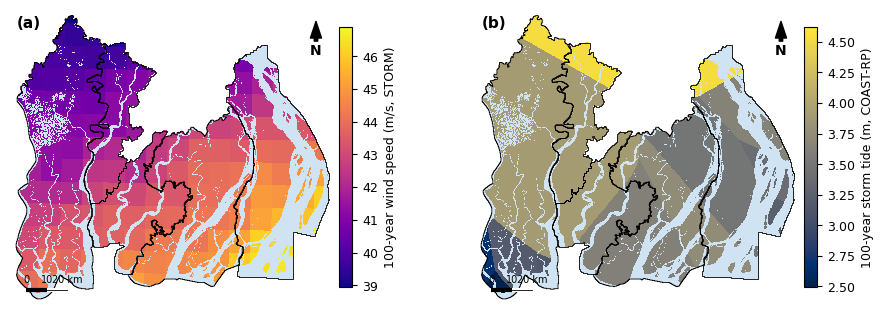

Saved: Fig3_04_Wind_StormTide.png
CELL 2 OK


In [2]:
# Notebook: P7_Figures_v02.ipynb | Cell 2: Chapter 3 figures (study area and input data)
lc = d  # model cells
# ---- Fig 3.1 Study area: (a) regional context with cyclone tracks, (b) districts and upazilas ----
ib = pd.read_csv(IBTRACS, skiprows=[1], usecols=["SID", "ISO_TIME", "LAT", "LON"], low_memory=False)
ib["LAT"] = pd.to_numeric(ib["LAT"], errors="coerce")
ib["LON"] = pd.to_numeric(ib["LON"], errors="coerce")
tracks = {}
for name, sid in STORMS.items():
    t = ib[ib["SID"] == sid].dropna(subset=["LAT", "LON"])
    assert len(t) >= 5, f"Track {name} ({sid}) not found in IBTrACS"
    g = gpd.GeoSeries(gpd.points_from_xy(t["LON"], t["LAT"]), crs="EPSG:4326").to_crs(CRS)
    tracks[name] = np.column_stack([g.x, g.y])
    print(f"Track {name}: {len(t)} points")
country = None
cands = [p for p in (ROOT / "01_raw").rglob("*") if "adm0" in p.name.lower() and p.suffix.lower() in (".shp", ".gpkg")]
if cands:
    country = gpd.read_file(cands[0]).to_crs(CRS)
    print("Country outline:", cands[0].name)
else:
    print("No *adm0* file found in 01_raw: panel (a) is drawn without the national outline")

reg = gpd.GeoSeries(gpd.points_from_xy([85.5, 93.0], [18.0, 24.5]), crs="EPSG:4326").to_crs(CRS)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
if country is not None:
    country.plot(ax=ax, color="#f2efe6", edgecolor="0.4", linewidth=0.5, zorder=1)
DIST.plot(ax=ax, color="#9ecae1", edgecolor="black", linewidth=0.4, zorder=2)
tcol = {"Amphan": "#d7301f", "Yaas": "#2171b5", "Remal": "#238b45"}
for name, xy in tracks.items():
    ax.plot(xy[:, 0], xy[:, 1], "-o", color=tcol[name], ms=2, lw=1.2, label=f"{name}", zorder=3)
ax.set_xlim(reg.x.min(), reg.x.max())
ax.set_ylim(reg.y.min(), reg.y.max())
ax.set_aspect("equal")
for lon in [86, 88, 90, 92]:                       # lat/lon graticule drawn in the map CRS
    gl = gpd.GeoSeries(gpd.points_from_xy([lon] * 50, np.linspace(17, 25.5, 50)), crs="EPSG:4326").to_crs(CRS)
    ax.plot(gl.x, gl.y, color="0.75", lw=0.4, zorder=0)
    ax.text(gl.x.iloc[0], reg.y.min(), f"{lon}°E", ha="center", va="top", fontsize=7)
for lat in [19, 21, 23]:
    gl = gpd.GeoSeries(gpd.points_from_xy(np.linspace(85, 93.5, 50), [lat] * 50), crs="EPSG:4326").to_crs(CRS)
    ax.plot(gl.x, gl.y, color="0.75", lw=0.4, zorder=0)
    ax.text(reg.x.min(), np.interp(reg.x.min(), gl.x, gl.y), f"{lat}°N ", ha="right", va="center", fontsize=7)
ax.set_xlim(reg.x.min(), reg.x.max())
ax.set_ylim(reg.y.min(), reg.y.max())
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
ax.legend(title="IBTrACS v04r01 track", loc="upper left", bbox_to_anchor=(0.0, 0.92))
north_arrow(ax)
scale_bar(ax, length_km=200)
ax.text(0.02, 0.98, "(a)", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
ax = axes[1]
pal = ["#fbb4ae", "#b3cde3", "#ccebc5", "#decbe4", "#fed9a6"]
for (i, r), c in zip(DIST.iterrows(), pal):
    gpd.GeoSeries([r.geometry], crs=CRS).plot(ax=ax, color=c, zorder=1)
base_map(ax, letter="b", upazila=True)
for _, r in DIST.iterrows():
    p = r.geometry.representative_point()
    ax.text(p.x, p.y, r["District"], ha="center", va="center", fontsize=9, fontweight="bold", zorder=7,
            bbox=dict(facecolor="white", alpha=0.7, lw=0, pad=1))
save(fig, "Fig3_01_StudyArea_Tracks")

# ---- Fig 3.2 Hazard predictors ----
fig, axes = plt.subplots(2, 2, figsize=(10, 9.5))
specs = [("Elevation_Mean_m", "viridis", "Elevation (m, FABDEM)"), ("Slope_Mean_deg", "YlOrBr", "Slope (deg)"),
         ("Distance_to_River_m", "Blues_r", "Distance to river (km)"), ("Cropland_Fraction", "YlGn", "Cropland fraction")]
for ax, (c, cmap, lab), L in zip(axes.ravel(), specs, "abcd"):
    v = lc[c] / 1000 if c == "Distance_to_River_m" else lc[c]
    lo, hi = np.nanpercentile(v, [2, 98])
    show_cont(ax, lc["Grid_ID"], v, cmap, lab, fig, vmin=lo, vmax=hi, extend="both")
    base_map(ax, letter=L)
save(fig, "Fig3_02_Hazard_Predictors")

# ---- Fig 3.3 Exposure and vulnerability inputs ----
fig, axes = plt.subplots(2, 2, figsize=(10, 9.5))
specs = [(np.log10(1 + lc["Population_Count"]), "magma_r", "log10(1 + people per cell)"),
         (lc["Poverty_Rate_Upazila_Pct"], "OrRd", "Upazila poverty rate (%)"),
         (lc["Distance_to_Hospital_m"] / 1000, "PuRd", "Distance to hospital (km)"),
         (lc["Distance_to_Road_m"] / 1000, "PuRd", "Distance to road (km)")]
for ax, (v, cmap, lab), L in zip(axes.ravel(), specs, "abcd"):
    lo, hi = np.nanpercentile(v, [1, 99])
    show_cont(ax, lc["Grid_ID"], v, cmap, lab, fig, vmin=lo, vmax=hi, extend="max")
    base_map(ax, letter=L)
save(fig, "Fig3_03_Exposure_Vulnerability_Inputs")

# ---- Fig 3.4 Wind and storm-tide hazard ----
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
show_cont(axes[0], lc["Grid_ID"], lc["Wind_RP100yr_ms"], "plasma", "100-year wind speed (m/s, STORM)", fig)
base_map(axes[0], letter="a")
show_cont(axes[1], lc["Grid_ID"], lc["Storm_Tide_RP100yr_m"], "cividis", "100-year storm tide (m, COAST-RP)", fig)
base_map(axes[1], letter="b")
save(fig, "Fig3_04_Wind_StormTide")
print("CELL 2 OK")


Training cells: 49,573 | blocks: 73 | folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


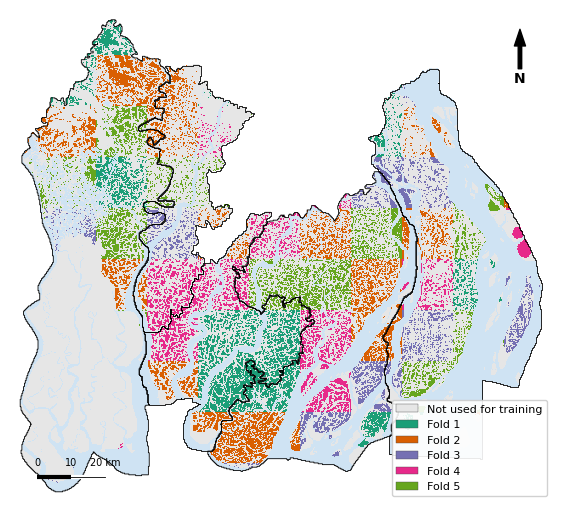

Saved: Fig4_01_Spatial_Blocks_Folds.png
                     Cells        Pop  Cells_Pct  Pop_Pct
Unobservable_Reason                                      
Mangrove             29017    15111.7       18.0      0.2
Observable           56174  1508427.4       34.9     19.5
Tree_And_Mangrove     1183    18006.3        0.7      0.2
Tree_Canopy          74500  6183570.4       46.3     80.0


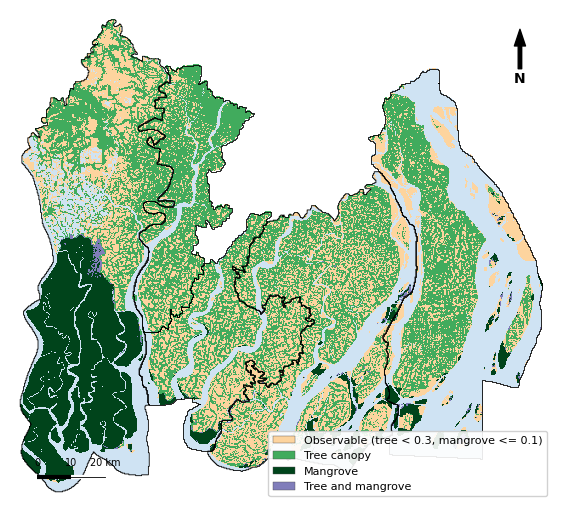

Saved: Fig4_02_Observability_Mask.png
CELL 3 OK


In [3]:
# Notebook: P7_Figures_v02.ipynb | Cell 3: Chapter 4 figures (spatial blocks, observability mask)
oof = pd.read_csv(MODELS / "final_v03" / "oof_v03.csv")
cf = oof.drop_duplicates("Grid_ID")[["Grid_ID", "Block_ID", "Fold"]]
assert cf.groupby("Grid_ID")["Fold"].nunique().max() == 1
print(f"Training cells: {len(cf):,} | blocks: {cf['Block_ID'].nunique()} | folds: {sorted(cf['Fold'].unique())}")
folds = sorted(cf["Fold"].unique())
fold_code = {f: i + 2 for i, f in enumerate(folds)}           # 1 = not used for training
code = d[["Grid_ID"]].merge(cf, on="Grid_ID", how="left")
code = np.where(code["Fold"].isna(), 1, code["Fold"].map(fold_code))
cols = ["#e6e6e6"] + ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"][:len(folds)]
labs = ["Not used for training"] + [f"Fold {i + 1}" for i in range(len(folds))]
fig, ax = plt.subplots(figsize=(7, 6.5))
show_cat(ax, d["Grid_ID"], code, cols, labs)
base_map(ax)
save(fig, "Fig4_01_Spatial_Blocks_Folds")

order = ["Observable", "Tree_Canopy", "Mangrove", "Tree_And_Mangrove"]
assert set(d["Unobservable_Reason"].unique()) <= set(order), d["Unobservable_Reason"].unique()
codes = d["Unobservable_Reason"].map({k: i + 1 for i, k in enumerate(order)})
share = d.groupby("Unobservable_Reason").agg(Cells=("Grid_ID", "size"), Pop=("Population_Count", "sum"))
share["Cells_Pct"] = 100 * share["Cells"] / share["Cells"].sum()
share["Pop_Pct"] = 100 * share["Pop"] / share["Pop"].sum()
print(share.round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 6.5))
show_cat(ax, d["Grid_ID"], codes, ["#fdd49e", "#41ab5d", "#00441b", "#807dba"],
         ["Observable (tree < 0.3, mangrove <= 0.1)", "Tree canopy", "Mangrove", "Tree and mangrove"])
base_map(ax)
save(fig, "Fig4_02_Observability_Mask")
print("CELL 3 OK")


Amphan: labelled cells 152,417 | prevalence 2.64%
Yaas: labelled cells 152,417 | prevalence 1.55%
Remal: labelled cells 152,417 | prevalence 9.28%


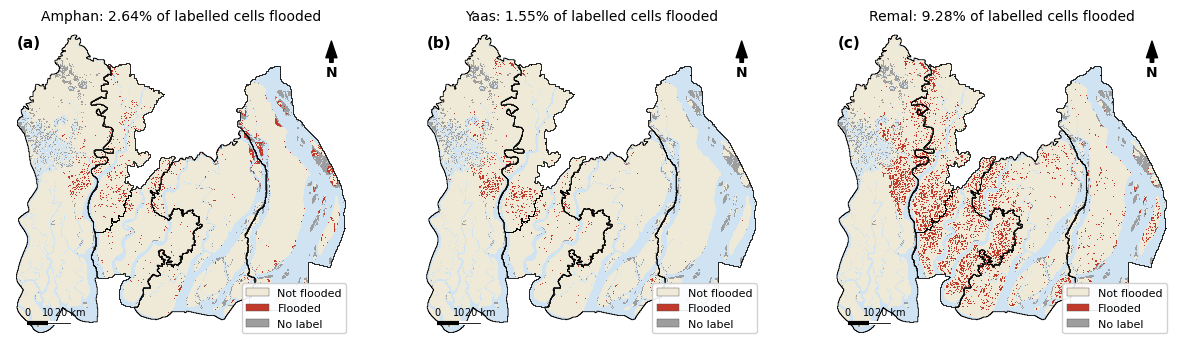

Saved: Fig5_01_SAR_Flood_Labels_by_Event.png


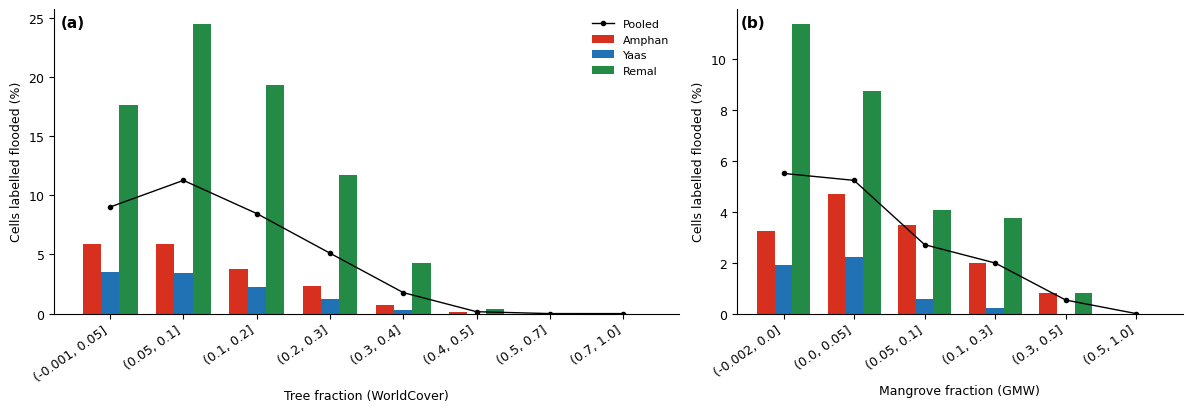

Saved: Fig5_02_LabelRate_vs_Canopy.png
CELL 4 OK


In [4]:
# Notebook: P7_Figures_v02.ipynb | Cell 4: Chapter 5 figures (flood labels and the canopy blind spot)
lab = pd.read_csv(LABELS, usecols=["Grid_ID", "Event_ID", "Flooded_Event"])
assert set(lab["Event_ID"].unique()) == set(EVENTS), lab["Event_ID"].unique()
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, ev, L in zip(axes, EVENTS, "abc"):
    e = d[["Grid_ID"]].merge(lab[lab["Event_ID"] == ev], on="Grid_ID", how="left")
    code = np.where(e["Flooded_Event"].isna(), 3, np.where(e["Flooded_Event"] == 1, 2, 1))
    prev = 100 * e["Flooded_Event"].mean()
    show_cat(ax, d["Grid_ID"], code, ["#efe9d8", "#c0392b", "#9e9e9e"], ["Not flooded", "Flooded", "No label"])
    base_map(ax, letter=L, title=f"{ev}: {prev:.2f}% of labelled cells flooded")
    print(f"{ev}: labelled cells {e['Flooded_Event'].notna().sum():,} | prevalence {prev:.2f}%")
save(fig, "Fig5_01_SAR_Flood_Labels_by_Event")

rt = pd.read_csv(MODELS / "diagnostics_v03" / "D1_rate_by_tree.csv")
rm = pd.read_csv(MODELS / "diagnostics_v03" / "D1_rate_by_mangrove.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
for ax, t, xcol, xl, L in [(axes[0], rt, "Tree_Fraction", "Tree fraction (WorldCover)", "a"),
                            (axes[1], rm, "Mangrove_Fraction_GMW", "Mangrove fraction (GMW)", "b")]:
    x = np.arange(len(t))
    w = 0.25
    for i, (ev, c) in enumerate(zip(EVENTS, ["#d7301f", "#2171b5", "#238b45"])):
        ax.bar(x + (i - 1) * w, t[f"Lab_{ev}_Pct"], w, color=c, label=ev)
    ax.plot(x, t["Pooled_Rate_Pct"], "k-o", ms=3, lw=1, label="Pooled")
    ax.set_xticks(x)
    ax.set_xticklabels(t[xcol].astype(str), rotation=35, ha="right")
    ax.set_xlabel(xl)
    ax.set_ylabel("Cells labelled flooded (%)")
    ax.text(0.01, 0.98, f"({L})", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "Fig5_02_LabelRate_vs_Canopy")
print("CELL 4 OK")


Spearman hazard vs tree: v02 -0.656 | v03 -0.130  (recorded -0.656 / -0.130)


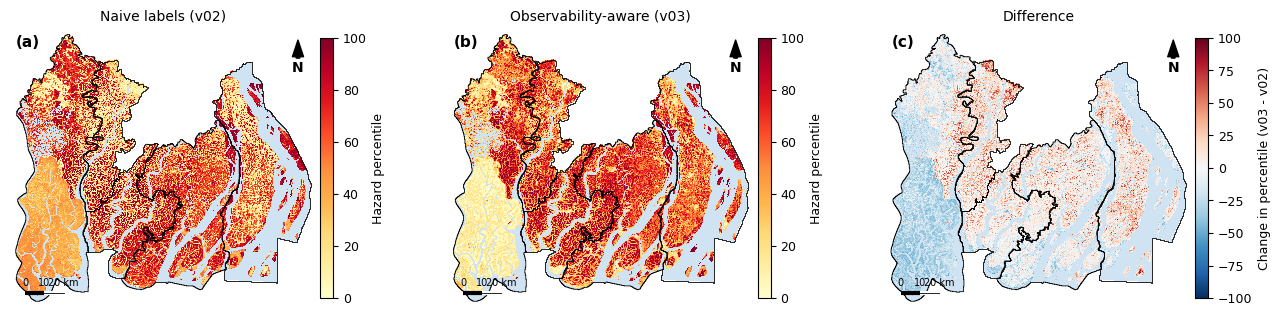

Saved: Fig5_03_Hazard_v02_vs_v03.png
LightGBM: ROC-AUC 0.7022 | PR-AUC 0.2553
Frequency Ratio: ROC-AUC 0.6971 | PR-AUC 0.2534
Random Forest: ROC-AUC 0.6949 | PR-AUC 0.2478
Logistic: ROC-AUC 0.6659 | PR-AUC 0.2014
Elevation only: ROC-AUC 0.5707 | PR-AUC 0.1439


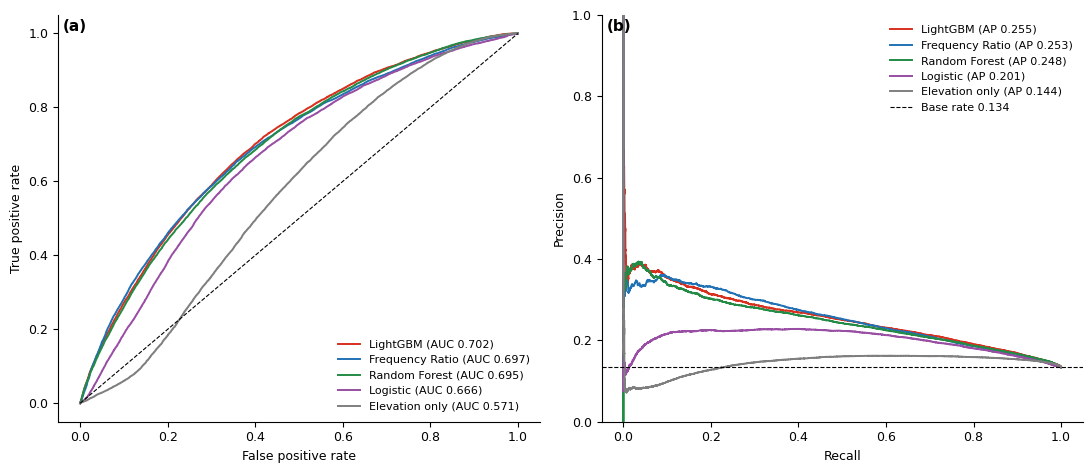

Saved: Fig5_04_ROC_PR_Curves.png


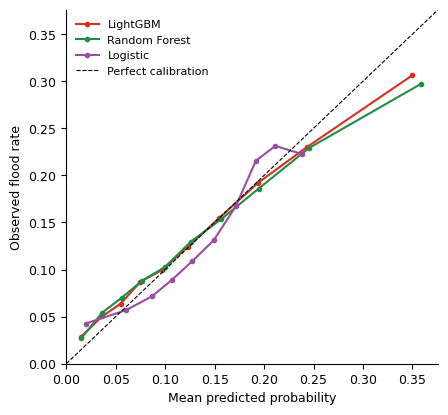

Saved: Fig5_05_Calibration.png


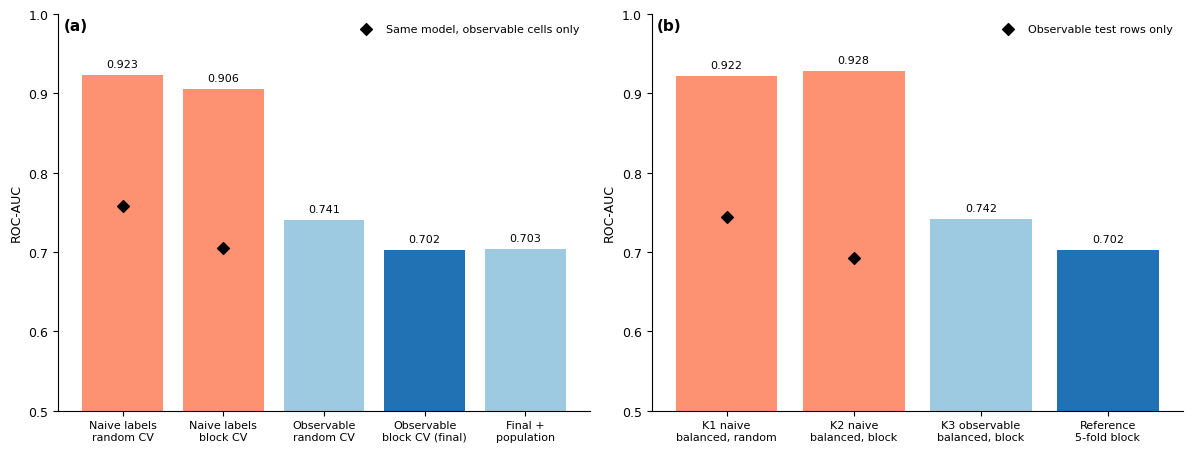

Saved: Fig5_06_Validation_Ladder_Protocol.png


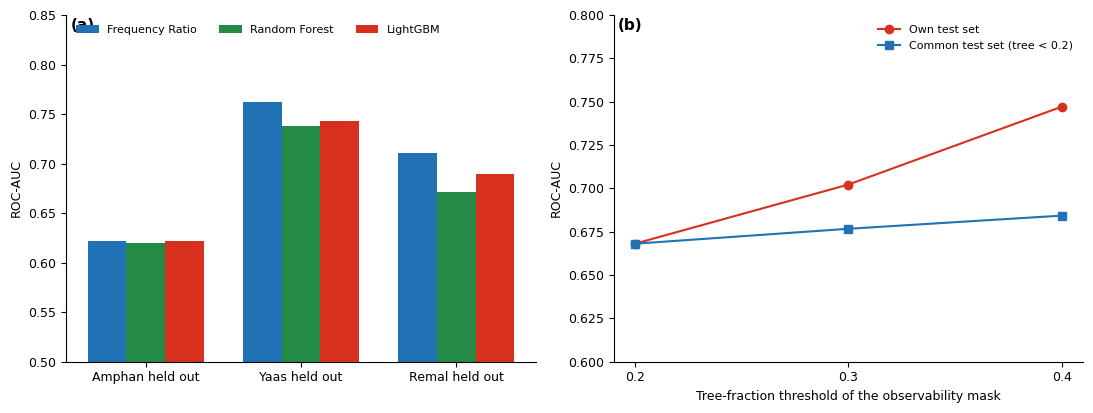

Saved: Fig5_07_LOEO_MaskSensitivity.png
CELL 5 OK


In [5]:
# Notebook: P7_Figures_v02.ipynb | Cell 5: Chapter 5 figures (naive vs corrected hazard, validation)
# ---- Fig 5.3 Hazard percentile: naive v02, corrected v03, difference ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
show_cont(axes[0], d["Grid_ID"], 100 * d["Pct_v02"], "YlOrRd", "Hazard percentile", fig, vmin=0, vmax=100)
base_map(axes[0], letter="a", title="Naive labels (v02)")
show_cont(axes[1], d["Grid_ID"], 100 * d["Pct_v03"], "YlOrRd", "Hazard percentile", fig, vmin=0, vmax=100)
base_map(axes[1], letter="b", title="Observability-aware (v03)")
diff = 100 * (d["Pct_v03"] - d["Pct_v02"])
show_cont(axes[2], d["Grid_ID"], diff, "RdBu_r", "Change in percentile (v03 - v02)", fig,
          norm=TwoSlopeNorm(vmin=-100, vcenter=0, vmax=100))
base_map(axes[2], letter="c", title="Difference")
rho_v02 = spearmanr(d["Hazard_Prob_LGBM_v02"], d["Tree_Fraction"]).correlation
rho_v03 = spearmanr(d["Hazard_Prob_LGBM"], d["Tree_Fraction"]).correlation
print(f"Spearman hazard vs tree: v02 {rho_v02:.3f} | v03 {rho_v03:.3f}  (recorded -0.656 / -0.130)")
save(fig, "Fig5_03_Hazard_v02_vs_v03")

# ---- Fig 5.4 ROC and PR curves (pooled out-of-fold, 15 km blocks) ----
oof = pd.read_csv(MODELS / "final_v03" / "oof_v03.csv")
met = pd.read_csv(MODELS / "final_v03" / "metrics_v03.csv")
y = oof["y"].astype(int).to_numpy()
mods = [("LGBM", "LightGBM", "#d7301f"), ("FR", "Frequency Ratio", "#2171b5"), ("RF", "Random Forest", "#238b45"),
        ("Logistic", "Logistic", "#984ea3"), ("ElevOnly", "Elevation only", "#7f7f7f")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for k, name, c in mods:
    s = oof[k].to_numpy()
    auc, ap = roc_auc_score(y, s), average_precision_score(y, s)
    ref = met[(met["Model"] == k) & (met["Event"] == "Pooled")]["ROC_AUC"]
    if len(ref):
        assert abs(auc - float(ref.iloc[0])) < 0.002, f"{k}: ROC {auc:.4f} differs from metrics_v03 {float(ref.iloc[0]):.4f}"
    fpr, tpr, _ = roc_curve(y, s)
    pr, rc, _ = precision_recall_curve(y, s)
    axes[0].plot(fpr, tpr, color=c, lw=1.4, label=f"{name} (AUC {auc:.3f})")
    axes[1].plot(rc, pr, color=c, lw=1.4, label=f"{name} (AP {ap:.3f})")
    print(f"{name}: ROC-AUC {auc:.4f} | PR-AUC {ap:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].axhline(y.mean(), color="k", ls="--", lw=0.8, label=f"Base rate {y.mean():.3f}")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1))
for ax, L in zip(axes, "ab"):
    ax.legend(frameon=False, loc="lower right" if L == "a" else "upper right")
    ax.text(0.01, 0.99, f"({L})", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "Fig5_04_ROC_PR_Curves")

# ---- Fig 5.5 Calibration ----
rel = pd.read_csv(MODELS / "final_v03" / "reliability_v03.csv")
fig, ax = plt.subplots(figsize=(4.8, 4.6))
for k, name, c in [("LGBM", "LightGBM", "#d7301f"), ("RF", "Random Forest", "#238b45"), ("Logistic", "Logistic", "#984ea3")]:
    r = rel[rel["Model"] == k].sort_values("Mean_Pred")
    ax.plot(r["Mean_Pred"], r["Obs_Rate"], "-o", ms=3, color=c, label=name)
lim = float(max(rel["Mean_Pred"].max(), rel["Obs_Rate"].max())) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=0.8, label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed flood rate", xlim=(0, lim), ylim=(0, lim))
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save(fig, "Fig5_05_Calibration")

# ---- Fig 5.6 Validation ladder and published-protocol emulation ----
lad = pd.read_csv(MODELS / "q1_ladder_v01" / "ladder_results_v01.csv")
kp = pd.read_csv(MODELS / "q1_extra_v01" / "kuet_style_protocol_v01.csv")
names = {"1_Naive_Random": "Naive labels\nrandom CV", "2_Naive_Block": "Naive labels\nblock CV",
         "3_Honest_Random": "Observable\nrandom CV", "4_Honest_Block": "Observable\nblock CV (final)",
         "5_Honest_Block_Plus_Pop": "Final +\npopulation"}
assert set(lad["Config"]) == set(names), lad["Config"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
x = np.arange(len(lad))
ax.bar(x, lad["ROC_AUC"], color=["#fc9272", "#fc9272", "#9ecae1", "#2171b5", "#9ecae1"])
ax.scatter(x, lad["ROC_AUC_Observable_Only"], marker="D", color="black", zorder=3, label="Same model, observable cells only")
for xi, v in zip(x, lad["ROC_AUC"]):
    ax.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([names[c] for c in lad["Config"]], fontsize=8)
ax.set(ylabel="ROC-AUC", ylim=(0.5, 1.0))
ax.legend(frameon=False, loc="upper right")
ax = axes[1]
ref = float(lad.loc[lad["Config"] == "4_Honest_Block", "ROC_AUC"].iloc[0])
labs = ["K1 naive\nbalanced, random", "K2 naive\nbalanced, block", "K3 observable\nbalanced, block", "Reference\n5-fold block"]
vals = list(kp["ROC_AUC"]) + [ref]
obs = list(kp["ROC_AUC_Observable_Test_Only"].iloc[:2]) + [np.nan, np.nan]
x = np.arange(len(vals))
ax.bar(x, vals, color=["#fc9272", "#fc9272", "#9ecae1", "#2171b5"])
ax.scatter(x, obs, marker="D", color="black", zorder=3, label="Observable test rows only")
for xi, v in zip(x, vals):
    ax.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labs, fontsize=8)
ax.set(ylabel="ROC-AUC", ylim=(0.5, 1.0))
ax.legend(frameon=False, loc="upper right")
for ax, L in zip(axes, "ab"):
    ax.text(0.01, 0.99, f"({L})", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "Fig5_06_Validation_Ladder_Protocol")

# ---- Fig 5.7 Leave-one-event-out and mask-threshold sensitivity ----
lo = pd.read_csv(MODELS / "final_v03" / "loeo_v03.csv")
ms = pd.read_csv(MODELS / "q1_extra_v01" / "mask_threshold_sensitivity_v01.csv").sort_values("Tree_Threshold")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
x = np.arange(len(EVENTS))
for i, (k, name, c) in enumerate([("FR", "Frequency Ratio", "#2171b5"), ("RF", "Random Forest", "#238b45"), ("LGBM", "LightGBM", "#d7301f")]):
    v = [float(lo[(lo["Held_Out_Event"] == e) & (lo["Model"] == k)]["LOEO_ROC"].iloc[0]) for e in EVENTS]
    ax.bar(x + (i - 1) * 0.25, v, 0.25, color=c, label=name)
ax.set_xticks(x); ax.set_xticklabels([f"{e} held out" for e in EVENTS])
ax.set(ylabel="ROC-AUC", ylim=(0.5, 0.85))
ax.legend(frameon=False, ncol=3, loc="upper left")
ax = axes[1]
ax.plot(ms["Tree_Threshold"], ms["ROC_AUC"], "-o", color="#d7301f", label="Own test set")
ax.plot(ms["Tree_Threshold"], ms["ROC_AUC_Common_Tree02"], "-s", color="#2171b5", label="Common test set (tree < 0.2)")
ax.set_xticks(ms["Tree_Threshold"])
ax.set(xlabel="Tree-fraction threshold of the observability mask", ylabel="ROC-AUC", ylim=(0.6, 0.8))
ax.legend(frameon=False)
for ax, L in zip(axes, "ab"):
    ax.text(0.01, 0.99, f"({L})", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save(fig, "Fig5_07_LOEO_MaskSensitivity")
print("CELL 5 OK")


Cells within AOA: 86,151 (53.6%)


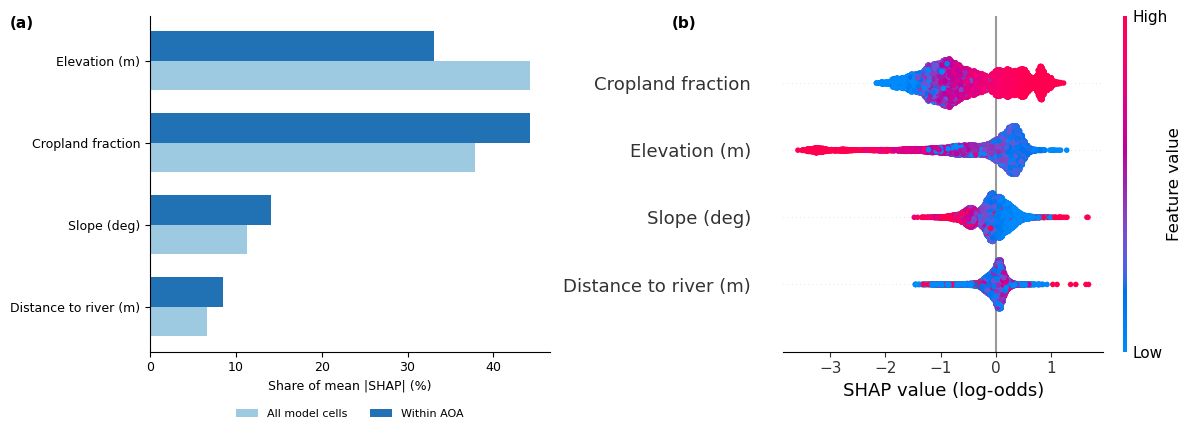

Saved: Fig5_08_SHAP_Importance_Beeswarm.png


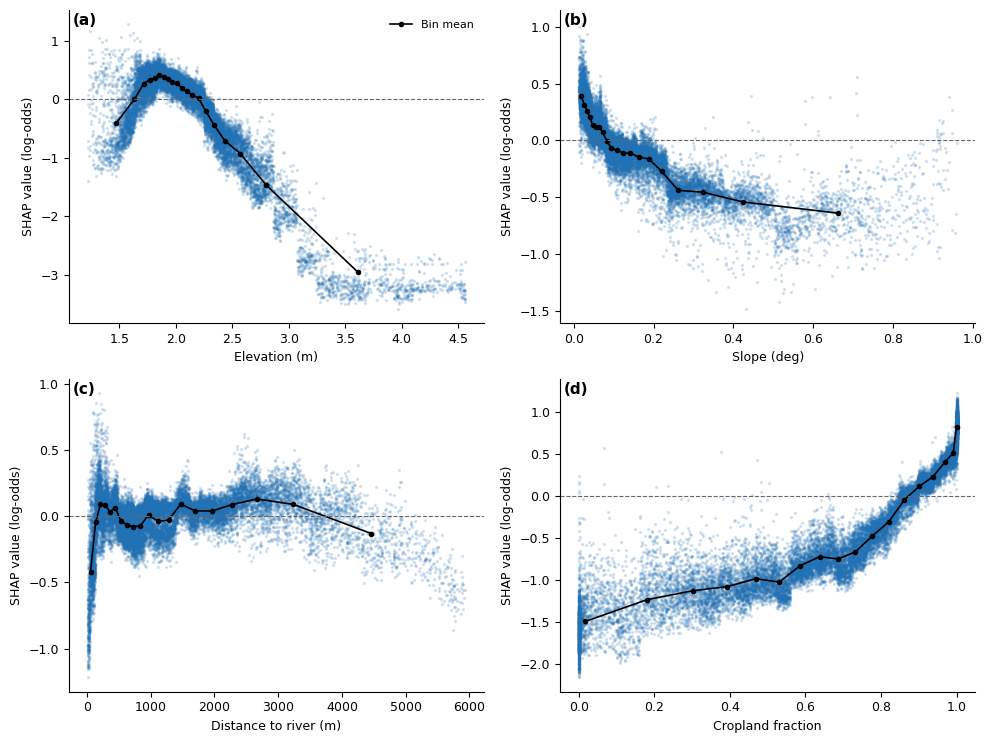

Saved: Fig5_09_SHAP_Dependence.png
Dominant_Increasing_Driver
Elevation_Mean_m       24.9
Distance_to_River_m    24.4
None                   23.0
Slope_Mean_deg         15.1
Cropland_Fraction      12.6


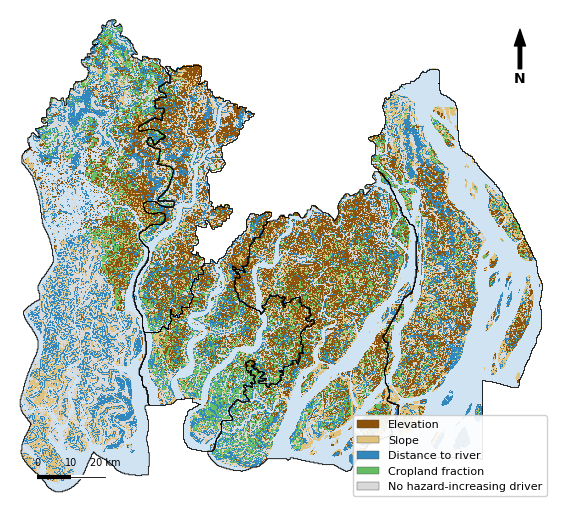

Saved: Fig5_10_Dominant_Driver.png


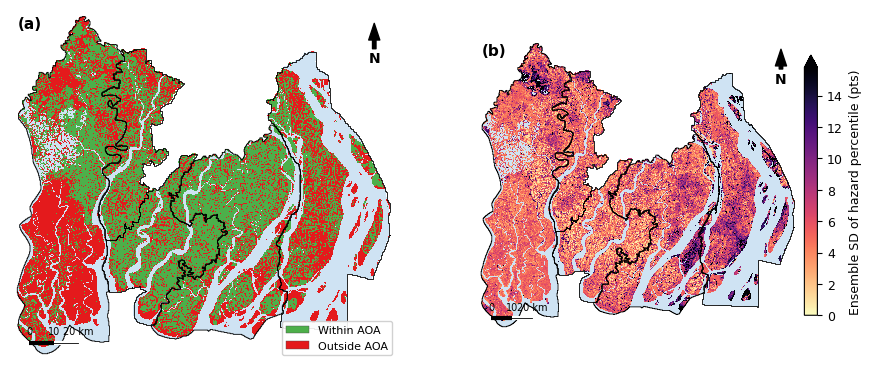

Saved: Fig5_11_AOA_Uncertainty.png
CELL 6 OK


In [6]:
# Notebook: P7_Figures_v02.ipynb | Cell 6: SHAP figures (global importance, beeswarm, dependence, driver map, AOA)
import shap
gi = pd.read_csv(MODELS / "phase4_v01" / "shap_global_importance_v01.csv").set_index("Feature").loc[FEATS]
gi = gi.sort_values("Share_All_Pct")              # largest at the top
aoa = d[d["Is_Within_AOA"] == 1]
print(f"Cells within AOA: {len(aoa):,} ({100 * len(aoa) / len(d):.1f}%)")
smp = aoa.sample(n=min(20000, len(aoa)), random_state=SEED)
S = smp[[f"SHAP_LogOdds_{f}" for f in FEATS]].to_numpy()
X = smp[FEATS].rename(columns=FEAT_LABEL)

# ---- Fig 5.8 (a) share of mean |SHAP|, (b) beeswarm within the AOA ----
fig = plt.figure(figsize=(12, 4.4))
ax = fig.add_subplot(1, 2, 1)
yy = np.arange(len(gi))
ax.barh(yy - 0.18, gi["Share_All_Pct"], 0.36, color="#9ecae1", label="All model cells")
ax.barh(yy + 0.18, gi["Share_AOA_Pct"], 0.36, color="#2171b5", label="Within AOA")
ax.set_yticks(yy); ax.set_yticklabels([FEAT_LABEL[f] for f in gi.index])
ax.set_xlabel("Share of mean |SHAP| (%)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.text(-0.35, 1.0, "(a)", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top")
ax2 = fig.add_subplot(1, 2, 2)
plt.sca(ax2)
shap.summary_plot(S, X, show=False, plot_size=None, color_bar=True)
ax2.set_xlabel("SHAP value (log-odds)")
ax2.text(-0.35, 1.0, "(b)", transform=ax2.transAxes, fontsize=11, fontweight="bold", va="top")
fig.tight_layout()
save(fig, "Fig5_08_SHAP_Importance_Beeswarm")

# ---- Fig 5.9 Dependence plots within the AOA ----
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for ax, f, L in zip(axes.ravel(), FEATS, "abcd"):
    xv, sv = smp[f].to_numpy(), smp[f"SHAP_LogOdds_{f}"].to_numpy()
    lo_, hi_ = np.percentile(xv, [1, 99])
    k = (xv >= lo_) & (xv <= hi_)
    ax.scatter(xv[k], sv[k], s=2, alpha=0.15, color="#2171b5", rasterized=True)
    bins = np.unique(np.quantile(xv[k], np.linspace(0, 1, 21)))
    idx = np.clip(np.digitize(xv[k], bins) - 1, 0, len(bins) - 2)
    mx = [xv[k][idx == i].mean() for i in range(len(bins) - 1) if (idx == i).any()]
    my = [sv[k][idx == i].mean() for i in range(len(bins) - 1) if (idx == i).any()]
    ax.plot(mx, my, "k-o", ms=3, lw=1.2, label="Bin mean")
    ax.axhline(0, color="0.4", lw=0.8, ls="--")
    ax.set(xlabel=FEAT_LABEL[f], ylabel="SHAP value (log-odds)")
    ax.text(0.01, 0.99, f"({L})", transform=ax.transAxes, ha="left", va="top", fontsize=11, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, loc="upper right")
fig.tight_layout()
save(fig, "Fig5_09_SHAP_Dependence")

# ---- Fig 5.10 Dominant hazard-increasing driver ----
drv = d["Dominant_Increasing_Driver"].fillna("None")
order = FEATS + ["None"]
assert set(drv.unique()) <= set(order), drv.unique()
dlab = [FEAT_LABEL[f].split(" (")[0] for f in FEATS] + ["No hazard-increasing driver"]
fig, ax = plt.subplots(figsize=(7, 6.5))
show_cat(ax, d["Grid_ID"], drv.map({k: i + 1 for i, k in enumerate(order)}),
         ["#8c510a", "#dfc27d", "#3288bd", "#66bd63", "#d9d9d9"], dlab)
base_map(ax)
print((drv.value_counts(normalize=True) * 100).round(1).to_string())
save(fig, "Fig5_10_Dominant_Driver")

# ---- Fig 5.11 Area of applicability and ensemble uncertainty ----
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
show_cat(axes[0], d["Grid_ID"], np.where(d["Is_Within_AOA"] == 1, 1, 2), ["#4daf4a", "#e41a1c"],
         ["Within AOA", "Outside AOA"])
base_map(axes[0], letter="a")
sd = d["Hazard_Ens_Rank_SD_Pct"]
show_cont(axes[1], d["Grid_ID"], sd, "magma_r", "Ensemble SD of hazard percentile (pts)", fig,
          vmin=0, vmax=float(np.percentile(sd, 98)), extend="max")
base_map(axes[1], letter="b")
save(fig, "Fig5_11_AOA_Uncertainty")
print("CELL 6 OK")


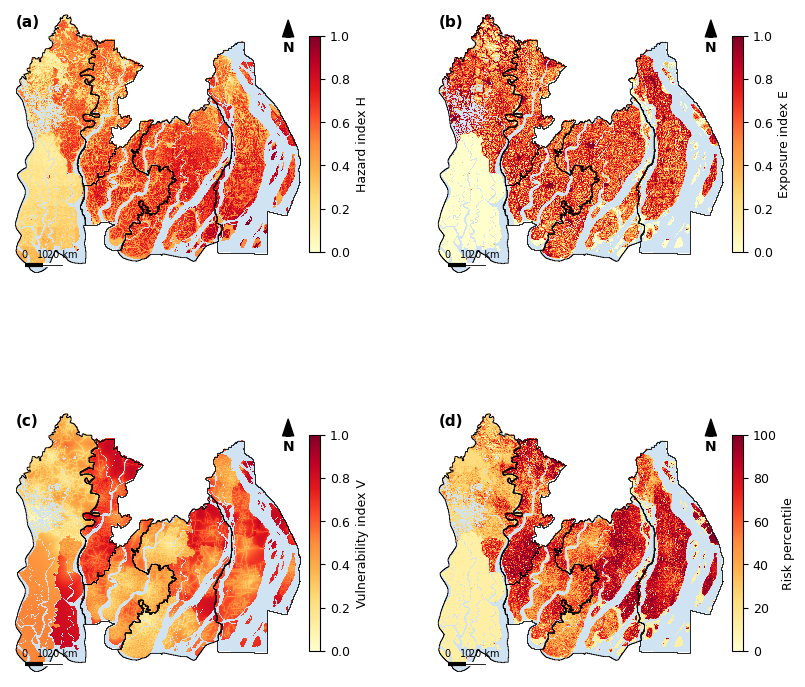

Saved: Fig5_12_Hazard_Exposure_Vulnerability_Risk.png
Median 90% MC interval width: 11.1 pts (recorded 11.1)
Top-10% cells: 16,088 | within AOA 60.5% (recorded 60.5%)


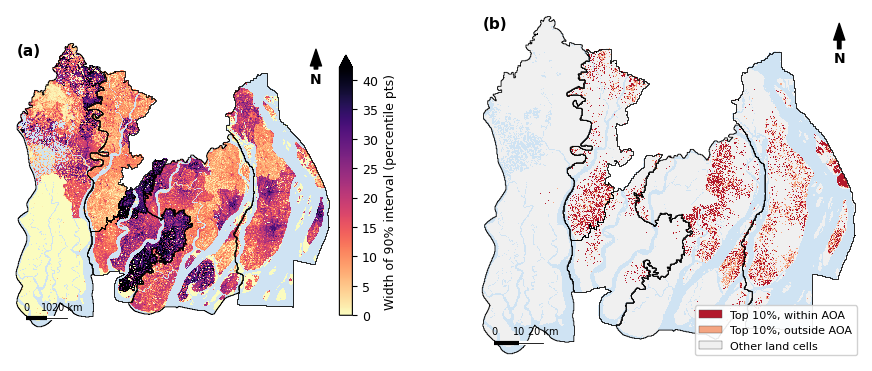

Saved: Fig5_13_Risk_Uncertainty_Top10.png
SSP245_2100: mean change 3.54 pts | cells beyond +/-20: 0.02%
SSP585_2100: mean change 4.45 pts | cells beyond +/-20: 0.29%


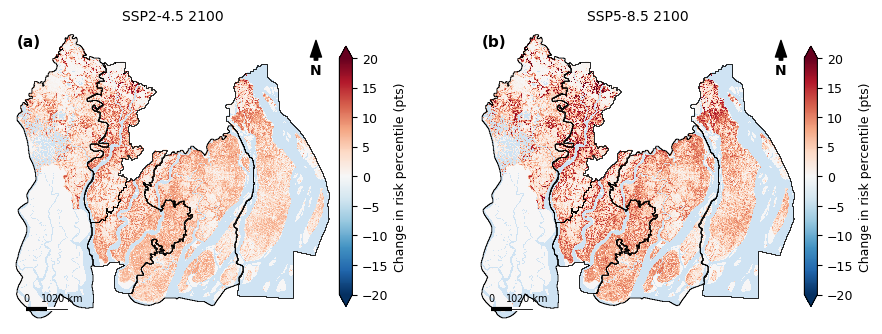

Saved: Fig5_14_SSP_Risk_Change_2100.png


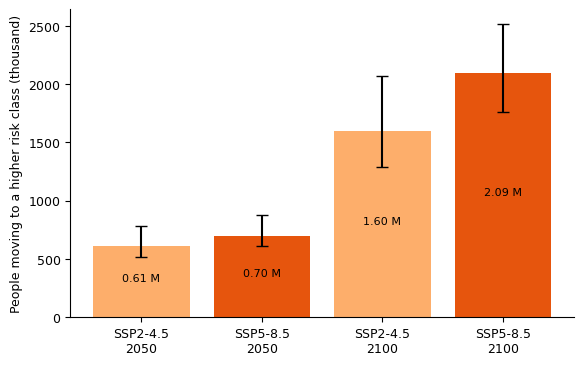

Saved: Fig5_15_SSP_People_Moving_Up.png
CELL 7 OK


In [7]:
# Notebook: P7_Figures_v02.ipynb | Cell 7: risk and scenario figures
# ---- Fig 5.12 Hazard, exposure, vulnerability and risk ----
fig, axes = plt.subplots(2, 2, figsize=(10, 9.5))
specs = [("H_Index", "Hazard index H", 1), ("E_Index", "Exposure index E", 1),
         ("V_Index", "Vulnerability index V", 1), ("Risk_Rank_Pct", "Risk percentile", 100)]
for ax, (c, lab, top), L in zip(axes.ravel(), specs, "abcd"):
    show_cont(ax, d["Grid_ID"], d[c], "YlOrRd", lab, fig, vmin=0, vmax=top)
    base_map(ax, letter=L)
save(fig, "Fig5_12_Hazard_Exposure_Vulnerability_Risk")

# ---- Fig 5.13 Monte Carlo uncertainty and top-10% cells by AOA status ----
width = d["Risk_MC_Rank_P95_Pct"] - d["Risk_MC_Rank_P05_Pct"]
assert (width >= -1e-9).all()
print(f"Median 90% MC interval width: {width.median():.1f} pts (recorded 11.1)")
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
show_cont(axes[0], d["Grid_ID"], width, "magma_r", "Width of 90% interval (percentile pts)", fig,
          vmin=0, vmax=float(np.percentile(width, 98)), extend="max")
base_map(axes[0], letter="a")
top = d["Is_Top10_Risk"] == 1
code = np.where(top & (d["Is_Within_AOA"] == 1), 1, np.where(top, 2, 3))
show_cat(axes[1], d["Grid_ID"], code, ["#b2182b", "#f4a582", "#f0f0f0"],
         ["Top 10%, within AOA", "Top 10%, outside AOA", "Other land cells"])
base_map(axes[1], letter="b")
print(f"Top-10% cells: {int(top.sum()):,} | within AOA {100 * (top & (d['Is_Within_AOA'] == 1)).sum() / top.sum():.1f}% (recorded 60.5%)")
save(fig, "Fig5_13_Risk_Uncertainty_Top10")

# ---- Fig 5.14 Change in risk percentile by 2100 (bathtub storm-tide proxy) ----
LIM = 20
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, s, L in zip(axes, ["SSP245_2100", "SSP585_2100"], "ab"):
    ch = d[f"Risk_Rank_Pct_{s}"] - d["Risk_Rank_Pct"]
    print(f"{s}: mean change {ch.mean():.2f} pts | cells beyond +/-{LIM}: {100 * (ch.abs() > LIM).mean():.2f}%")
    show_cont(ax, d["Grid_ID"], ch, "RdBu_r", "Change in risk percentile (pts)", fig,
              norm=TwoSlopeNorm(vmin=-LIM, vcenter=0, vmax=LIM), extend="both")
    base_map(ax, letter=L, title=s.replace("_", " ").replace("SSP245", "SSP2-4.5").replace("SSP585", "SSP5-8.5"))
save(fig, "Fig5_14_SSP_Risk_Change_2100")

ss = pd.read_csv(MODELS / "phase5_v01" / "ssp_summary_v01.csv")
fig, ax = plt.subplots(figsize=(6.5, 4))
lab_, med, lo_, hi_ = [], [], [], []
for yr in [2050, 2100]:
    for sp, nm in [("SSP245", "SSP2-4.5"), ("SSP585", "SSP5-8.5")]:
        r = ss[(ss["SSP"] == sp) & (ss["Year"] == yr)].set_index("SLR_Level")["Pop_Up_k"]
        lab_.append(f"{nm}\n{yr}"); med.append(r["median"]); lo_.append(r["likely_low"]); hi_.append(r["likely_high"])
med, lo_, hi_ = np.array(med), np.array(lo_), np.array(hi_)
x = np.arange(len(med))
ax.bar(x, med, color=["#fdae6b", "#e6550d", "#fdae6b", "#e6550d"],
       yerr=[med - lo_, hi_ - med], capsize=4, ecolor="black")
for xi, v in zip(x, med):
    ax.text(xi, v * 0.5, f"{v / 1000:.2f} M", ha="center", color="black", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(lab_)
ax.set_ylabel("People moving to a higher risk class (thousand)")
ax.spines[["top", "right"]].set_visible(False)
save(fig, "Fig5_15_SSP_People_Moving_Up")
print("CELL 7 OK")


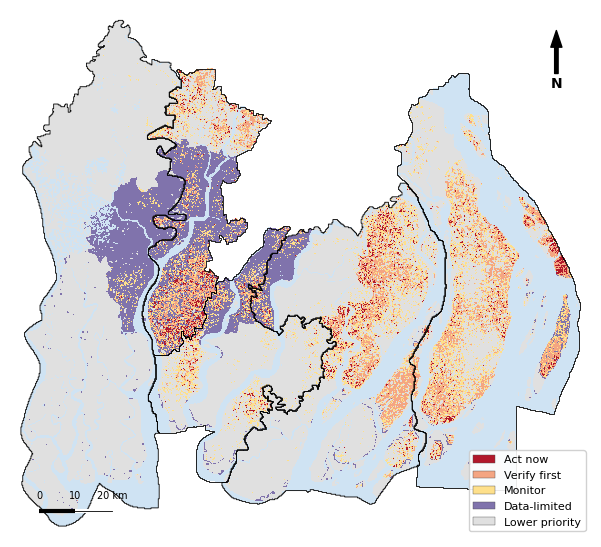

Saved: Fig5_16_Priority_Classes.png
         Group  Poverty_PopW_Pct  Population
       Act now              32.3    273503.8
  Verify first              30.8   1187128.0
       Monitor              28.3   1145912.4
  Data-limited              25.5   1108934.8
Lower priority              18.3   4009636.9
 Hidden hazard              27.1    319905.4
All land cells              23.2   7725115.8
(recorded: Act now 32.3, Verify 30.8, Monitor 28.3, Data-limited 25.5, Lower 18.3, hidden 27.1, all 23.2)


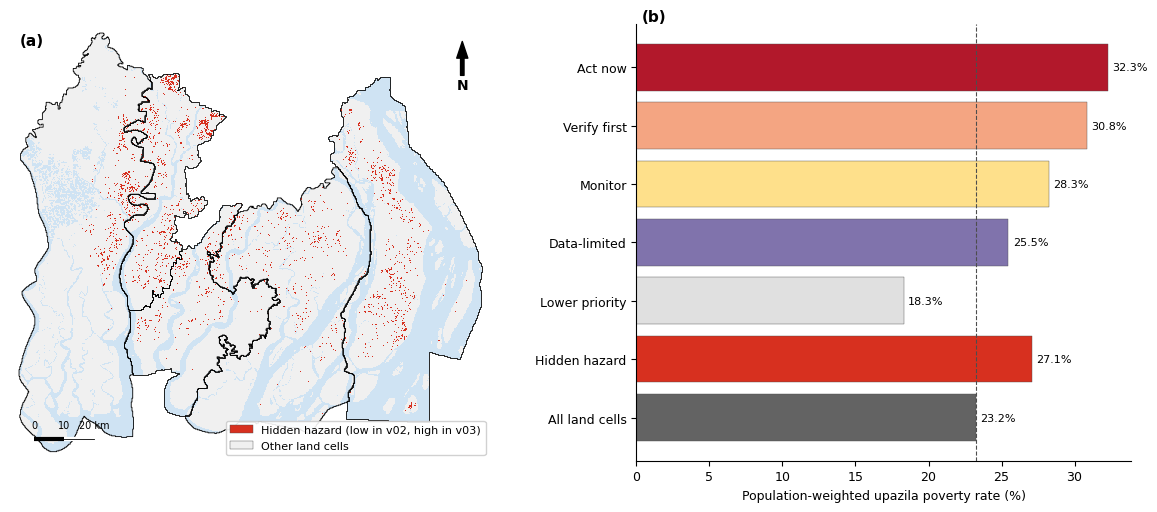

Saved: Fig5_17_HiddenHazard_Equity.png
NAWG upazilas: 23 | Spearman v03 -0.363 (recorded -0.363)


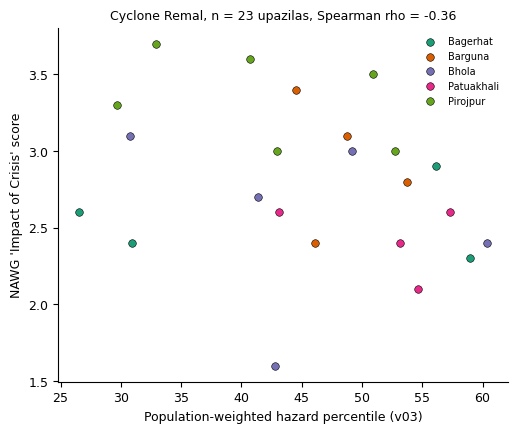

Saved: Fig5_18_NAWG_Scatter.png
CELL 8 OK


In [8]:
# Notebook: P7_Figures_v02.ipynb | Cell 8: priority, hidden hazard and independent-evidence figures
PCOL = ["#b2182b", "#f4a582", "#fee08b", "#8073ac", "#e0e0e0"]
PLAB = ["Act now", "Verify first", "Monitor", "Data-limited", "Lower priority"]
assert set(d["Priority_Class_Code"].unique()) <= {1, 2, 3, 4, 5}
fig, ax = plt.subplots(figsize=(7.5, 7))
show_cat(ax, d["Grid_ID"], d["Priority_Class_Code"], PCOL, PLAB)
base_map(ax)
save(fig, "Fig5_16_Priority_Classes")

pov = []
for c, nm in enumerate(PLAB, start=1):
    k = d["Priority_Class_Code"] == c
    pov.append((nm, wmean(d.loc[k, "Poverty_Rate_Upazila_Pct"], d.loc[k, "Population_Count"]),
                d.loc[k, "Population_Count"].sum()))
hid = d["Is_Hidden_Hazard"] == 1
pov.append(("Hidden hazard", wmean(d.loc[hid, "Poverty_Rate_Upazila_Pct"], d.loc[hid, "Population_Count"]),
            d.loc[hid, "Population_Count"].sum()))
pov.append(("All land cells", wmean(d["Poverty_Rate_Upazila_Pct"], d["Population_Count"]), d["Population_Count"].sum()))
pv = pd.DataFrame(pov, columns=["Group", "Poverty_PopW_Pct", "Population"])
print(pv.round(1).to_string(index=False))
print("(recorded: Act now 32.3, Verify 30.8, Monitor 28.3, Data-limited 25.5, Lower 18.3, hidden 27.1, all 23.2)")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
show_cat(axes[0], d["Grid_ID"], np.where(hid, 1, 2), ["#d7301f", "#f0f0f0"],
         ["Hidden hazard (low in v02, high in v03)", "Other land cells"])
base_map(axes[0], letter="a")
ax = axes[1]
cols_ = PCOL + ["#d7301f", "#636363"]
ax.barh(np.arange(len(pv))[::-1], pv["Poverty_PopW_Pct"], color=cols_, edgecolor="0.3", lw=0.3)
ax.set_yticks(np.arange(len(pv))[::-1]); ax.set_yticklabels(pv["Group"])
ax.axvline(pv["Poverty_PopW_Pct"].iloc[-1], color="0.3", ls="--", lw=0.8)
for yi, v in zip(np.arange(len(pv))[::-1], pv["Poverty_PopW_Pct"]):
    ax.text(v + 0.3, yi, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Population-weighted upazila poverty rate (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.01, 1.0, "(b)", transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")
fig.tight_layout()
save(fig, "Fig5_17_HiddenHazard_Equity")

nw = pd.read_csv(MODELS / "q1_nawg_v01" / "nawg_upazila_table_v01.csv")
nw = nw[nw["NAWG_Impact_Score"].notna()]
rho = spearmanr(nw["Hazard_Pct_PopW_v03"], nw["NAWG_Impact_Score"]).correlation
print(f"NAWG upazilas: {len(nw)} | Spearman v03 {rho:.3f} (recorded -0.363)")
dc = dict(zip(sorted(DIST["District"]), ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"]))
fig, ax = plt.subplots(figsize=(5.8, 4.6))
for dn, g in nw.groupby("District"):
    ax.scatter(100 * g["Hazard_Pct_PopW_v03"], g["NAWG_Impact_Score"], s=30, color=dc.get(dn, "k"),
               edgecolor="black", lw=0.4, label=dn)
ax.set(xlabel="Population-weighted hazard percentile (v03)", ylabel="NAWG 'Impact of Crisis' score")
ax.set_title(f"Cyclone Remal, n = {len(nw)} upazilas, Spearman rho = {rho:.2f}", fontsize=9)
ax.legend(frameon=False, fontsize=7)
ax.spines[["top", "right"]].set_visible(False)
save(fig, "Fig5_18_NAWG_Scatter")
print("CELL 8 OK")


In [9]:
# Notebook: P7_Figures_v02.ipynb | Cell 9: summary of saved figures
print(f"{len(SAVED)} figures saved in {OUT}:")
for s in SAVED:
    print("  ", s)
assert len(SAVED) == 24, f"Expected 24 figures, got {len(SAVED)}"
print("ALL FIGURES DONE")


24 figures saved in D:\Siam\Thesis_GeoAI\07_maps_figures\thesis_v02:
   Fig3_01_StudyArea_Tracks.png
   Fig3_02_Hazard_Predictors.png
   Fig3_03_Exposure_Vulnerability_Inputs.png
   Fig3_04_Wind_StormTide.png
   Fig4_01_Spatial_Blocks_Folds.png
   Fig4_02_Observability_Mask.png
   Fig5_01_SAR_Flood_Labels_by_Event.png
   Fig5_02_LabelRate_vs_Canopy.png
   Fig5_03_Hazard_v02_vs_v03.png
   Fig5_04_ROC_PR_Curves.png
   Fig5_05_Calibration.png
   Fig5_06_Validation_Ladder_Protocol.png
   Fig5_07_LOEO_MaskSensitivity.png
   Fig5_08_SHAP_Importance_Beeswarm.png
   Fig5_09_SHAP_Dependence.png
   Fig5_10_Dominant_Driver.png
   Fig5_11_AOA_Uncertainty.png
   Fig5_12_Hazard_Exposure_Vulnerability_Risk.png
   Fig5_13_Risk_Uncertainty_Top10.png
   Fig5_14_SSP_Risk_Change_2100.png
   Fig5_15_SSP_People_Moving_Up.png
   Fig5_16_Priority_Classes.png
   Fig5_17_HiddenHazard_Equity.png
   Fig5_18_NAWG_Scatter.png
ALL FIGURES DONE
